# Eligibility traces, part a: implementation

$n$-step temporal-difference (TD) prediction, the $\lambda$-return, TD($\lambda$) with three kinds of eligibility trace and true online TD($\lambda$), all run on the 19-state random walk and checked against the walk's exact values and against each other.
Companion to the chapter note: [Eligibility Traces: n-step TD and TD(λ)](../chapters/07a%20n-step%20TD%20and%20TD%28%CE%BB%29.md).

**Sections**
1. The 19-state random walk and its exact values
2. $n$-step returns and the $n$-step update
3. $n$-step TD on the random walk, on-line and off-line
4. The $\lambda$-return and its forward-view algorithm
5. TD($\lambda$): the backward view with eligibility traces
6. True online TD($\lambda$)
7. The methods side by side
8. Checkpoints

**Scale.** The book's counts are kept (100 repetitions of 10 episodes, the same walks for every method), so nothing is scaled down; the whole notebook runs in a few seconds.

**Not implemented.** Control and off-policy learning belong to part b. The chapter defers the real-time $\lambda$-return, the forward view that true online TD($\lambda$) matches exactly, to the function-approximation chapter, so true online TD($\lambda$) is compared here with the on-line $\lambda$-return as this chapter defines it, not with its real-time version. The convergence conditions for $n$-step methods are not stated in the chapter and are not tested.

In [1]:
from collections.abc import Callable, Sequence
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_WALKS, SEED_GEN, SEED_REDUCTION, SEED_LAMBDA, SEED_EQUIV, SEED_TRUE = 1, 2, 3, 4, 5, 6

N_STATES, START = 19, 10  # non-terminal states 1..19; the terminals are 0 (outcome -1) and 20 (outcome +1)
GAMMA, GAMMA_CHECK = 1.0, 0.9  # the task is undiscounted; GAMMA_CHECK exercises the discounted formulas
N_GEN = 10_000  # walks used to validate the walk generator
N_REPS, N_EPISODES = 100, 10  # the book's counts
MAX_STEPS = 2000  # random steps drawn per walk; a walk still running after that trips an assertion

ALPHAS = np.array([0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
NS = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512])
LAMS = np.array([0.0, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1.0])
LAM_ONE = np.array([1.0])

FAMILY_ALPHA = 0.05  # family-wise error rate of a group of simultaneous comparisons (Bonferroni)
EXACT_TOL = 1e-10  # expected rounding of sums of a few hundred terms of size up to 60 is below 1e-11; observed gaps are near 5e-14
REL_TOL = 1e-8  # relative tolerance for error curves built from many chained updates in two code paths
ERR_CAP = 100.0  # an error above this, or values that overflow, are scored as this (a diverged repetition)
DIVERGED = ERR_CAP / 2  # a mean error above this marks a diverged cell
LARGE_ERR = 1.0  # a repetition error above this counts as a large error

EX_ALPHA, EX_LAM, EX_V0 = 0.1, 0.8, 0.5  # step size, trace decay and start value of the five-state example
EX_NS = np.array([1, 2, 3, 4])
N_REDUCTION, N_CHECK = 8, (1, 4, 16)  # largest n of the error reduction check; n of the expected-return check
WORKED_LAM, WORKED_LEFT = 0.5, 3  # worked example of the lambda-return weights
WEIGHT_STEPS = (1, 2, 3, 7, 50)  # steps left at which the weights are checked to sum to 1

CHECK_REPS, CHECK_LEN = 40, 25  # walks in the exactness checks; target length of the walk checked by brute force
CHECK_ALPHAS, ONLINE_ALPHAS = (0.1, 0.5, 1.0), (0.01, 0.05, 0.1)  # step sizes of the exact and approximate checks
CHECK_LAMS = (0.0, 0.5, 0.9, 1.0)
SMALL_ALPHAS = np.array([1e-5, 3e-5, 1e-4, 3e-4, 1e-3])
SMALL_LAM = 0.9
SLOPE_TOL = 0.2  # allowed distance of the fitted log-log slope from 2

TRACE_VISITS = (2, 3, 8, 11, 12, 13, 14)  # times at which one state is visited in the trace picture
TRACE_STEPS, TRACE_ALPHA, TRACE_GL, TRACE_TICK = 22, 0.5, 0.8, 0.1  # length, dutch step size, gamma * lambda, tick height

ALPHA_HIGH = 0.5
LAM_LARGE, LAM_BLOWUP = 0.9, 0.99
BLOWUP_FACTOR = 10  # accumulating traces must be this many times worse than the lambda-return at LAM_BLOWUP
LAM_PROBE, ALPHA_PROBE = 0.95, 0.4  # a setting where accumulating traces first pass the start's error
LAM_BEST, PROBE_ALPHAS = 0.8, (0.2, 0.25, 0.3, 0.4, 0.5, 0.6)  # lambda and step sizes of the dutch against true online check

Y_LIMITS = (0.25, 0.55)  # vertical range of the error plots, as in the book's figures
FIG_WIDE = (12, 4)

## 1. The 19-state random walk and its exact values

The task is prediction on a row of 19 states with a terminal state at each end. Every step moves one state left or right with probability 1/2. An episode starts in the middle state; entering the left terminal pays $-1$, entering the right terminal pays $+1$, every other reward is 0, and there is no discounting ($\gamma = 1$), so the return of an episode is its outcome. The policy is fixed, so the job is to estimate its state values $v_\pi$.

- **Truth:** the values satisfy $v = b + \gamma Q v$, where $Q$ holds the move probabilities among the 19 states and $b$ the expected one-step reward, so $v = (I - \gamma Q)^{-1} b$ by a linear solve. A closed form, $(i - 10)/10$ in state $i$, gives an independent check.
- **Error measure:** the root-mean-square (RMS) error, the square root of the mean over the 19 states of the squared difference between estimate and truth, taken at the end of each episode.
- **Protocol (the book's):** all values start at 0; each method runs for 10 episodes; this is repeated 100 times, and every method sees the same 1,000 walks. A result is the RMS error averaged over the 10 episodes, then averaged over the repetitions, with its standard error: the sample standard deviation across repetitions divided by $\sqrt{100}$, the typical size of the noise in the average.
- **Layout:** states are indexed 0 to 20 and the two terminals always hold value 0. All repetitions are processed as arrays; in each episode the repetitions are sorted by length so that only those still running are updated, and the driver permutes the stored values to match.
- **Generator check:** the walk generator is validated on its own seed with 10,000 walks against the exact chain: mean length, share ending right, and the mean number of visits to each state, which the chain gives as the row of $(I - Q)^{-1}$ for the start state.

In [2]:
class Episode(NamedTuple):
    """One episode for each of R repetitions, rows sorted by length (longest first)."""

    S: np.ndarray  # (R, T_max + 1) state at each time; the terminal repeats after the end
    rew: np.ndarray  # (R, T_max) reward R_{t+1} received on leaving time t; zero after the end
    T: np.ndarray  # (R,) number of steps of each episode
    active: np.ndarray  # (T_max + 1,) number of rows still running at time t (a prefix of the rows)
    order: np.ndarray  # (R,) original repetition index of each row


def walk_episode(rng: np.random.Generator, n_walks: int) -> Episode:
    """`n_walks` independent walks from the middle state, left or right with probability 1/2 until a terminal."""
    steps = rng.integers(0, 2, (n_walks, MAX_STEPS), dtype=np.int8) * 2 - 1
    pos = START + np.cumsum(steps, axis=1, dtype=np.int16)
    hit = (pos == 0) | (pos == N_STATES + 1)
    assert hit.any(axis=1).all(), "a walk did not end within MAX_STEPS"
    T = hit.argmax(axis=1) + 1
    t = np.arange(T.max() + 1)
    path = np.concatenate([np.full((n_walks, 1), START), pos[:, : T.max()]], axis=1)
    S = np.take_along_axis(path, np.minimum(t[None, :], T[:, None]), axis=1)
    rew = ((S[:, 1:] == N_STATES + 1).astype(float) - (S[:, 1:] == 0)) * (t[None, :-1] < T[:, None])
    order = np.argsort(-T, kind="stable")
    return Episode(S[order], rew[order], T[order], (T[order][None, :] > t[:, None]).sum(axis=1), order)


def chain_truth(gamma: float = GAMMA) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """True values v_pi by a linear solve, the move matrix among the non-terminal states and the expected one-step reward."""
    Q = 0.5 * (np.eye(N_STATES, k=1) + np.eye(N_STATES, k=-1))
    b = np.zeros(N_STATES)
    b[0], b[-1] = -0.5, 0.5
    return np.linalg.solve(np.eye(N_STATES) - gamma * Q, b), Q, b


def rms_error(V: np.ndarray, v_true: np.ndarray) -> np.ndarray:
    """RMS error over the non-terminal states for V of shape (repetitions, states + 2, parameters, step sizes)."""
    return np.sqrt(np.mean((V[:, 1:-1] - v_true[None, :, None, None]) ** 2, axis=1))

In [3]:
v_true, Q, b = chain_truth()
closed_form = 2 * np.arange(1, N_STATES + 1) / (N_STATES + 1) - 1
initial_error = float(np.sqrt(np.mean(v_true**2)))
children = np.random.SeedSequence(SEED_WALKS).spawn(N_EPISODES)
walks = [walk_episode(np.random.default_rng(c), N_REPS) for c in children]
lengths = np.concatenate([ep.T for ep in walks])
ends_right = np.mean([ep.S[np.arange(N_REPS), ep.T] == N_STATES + 1 for ep in walks])

fundamental = np.linalg.inv(np.eye(N_STATES) - Q)
gen = walk_episode(np.random.default_rng(SEED_GEN), N_GEN)
alive = np.arange(gen.S.shape[1])[None, :] < gen.T[:, None]
visits = np.stack([((gen.S == s) & alive).sum(axis=1) for s in range(1, N_STATES + 1)])
right = gen.S[np.arange(N_GEN), gen.T] == N_STATES + 1
z_walk = np.concatenate(
    [
        [(gen.T.mean() - fundamental[START - 1].sum()) / (gen.T.std(ddof=1) / np.sqrt(N_GEN))],
        [(right.mean() - START / (N_STATES + 1)) / np.sqrt(0.25 / N_GEN)],
        (visits.mean(axis=1) - fundamental[START - 1]) / (visits.std(axis=1, ddof=1) / np.sqrt(N_GEN)),
    ]
)
z_limit_walk = stats.norm.isf(FAMILY_ALPHA / (2 * len(z_walk)))
print(f"Largest |v_solve - v_closed form| over the 19 states: {np.abs(v_true - closed_form).max():.2e}")
print(f"RMS error of the all-zero start: {initial_error:.4f}")
print(
    f"Generator check on {N_GEN} walks: mean length {gen.T.mean():.2f} (exact {fundamental[START - 1].sum():.2f}), share ending right {right.mean():.3f} (exact 0.5)"
)
print(
    f"Largest |z| of {len(z_walk)} comparisons with the exact chain: {np.abs(z_walk).max():.2f} (limit {z_limit_walk:.2f})"
)
print(
    f"The {N_REPS * N_EPISODES} experiment walks: mean length {lengths.mean():.2f}, share ending right {ends_right:.3f}, longest {lengths.max()} steps"
)
print(
    "Checkpoint: solved values equal the closed form (i - 10) / 10:",
    bool(np.abs(v_true - closed_form).max() < EXACT_TOL),
)
print("Checkpoint: simulated walks agree with the exact chain:", bool(np.abs(z_walk).max() < z_limit_walk))

Largest |v_solve - v_closed form| over the 19 states: 2.22e-16
RMS error of the all-zero start: 0.5477
Generator check on 10000 walks: mean length 100.46 (exact 100.00), share ending right 0.506 (exact 0.5)
Largest |z| of 21 comparisons with the exact chain: 1.50 (limit 3.04)
The 1000 experiment walks: mean length 101.37, share ending right 0.476, longest 552 steps
Checkpoint: solved values equal the closed form (i - 10) / 10: True
Checkpoint: simulated walks agree with the exact chain: True


### Reading the result

- The linear solve agrees with the closed form $(i - 10)/10$ to 2.22e-16, so the truth used throughout is confirmed by an independent route.
- A method that has learned nothing (all values 0) has RMS error 0.5477. This is the starting error of every run and the yardstick used below for "worse than not learning".
- The generator matches the exact chain: 10,000 walks have mean length 100.46 (exact 100.00) and end on the right in 0.506 of cases (exact 0.5). The largest of the 21 standardized differences (a $z$ score is a difference divided by its standard error) is 1.50. The limit 3.04 is a family-wise limit: when several comparisons are made at once, each is tested at level 0.05 divided by their number (here 21, two-sided), so that the chance that a correct generator fails any of them is at most 5%.
- The 1,000 walks of the experiment itself have mean length 101.37, end on the right in 0.476 of cases and the longest has 552 steps. All methods share these walks.

## 2. $n$-step returns and the $n$-step update

The return of an episode from time $t$ is $G_t$, the sum of the discounted rewards until the episode ends. An **$n$-step return** keeps the first $n$ rewards and replaces the rest by the current estimate of the value of the state reached after $n$ steps:

$$
G_t^{t+n} = R_{t+1} + \gamma R_{t+2} + \cdots + \gamma^{n-1} R_{t+n} + \gamma^n V_t(S_{t+n})
$$

If the episode ends before $t + n$, the return is the complete return $G_t$ (the terminal state's value is 0, so the same formula covers it). The $n$-step TD update moves only the visited state toward it:

$$
\Delta_t(S_t) = \alpha \big[ G_t^{t+n} - V_t(S_t) \big], \qquad V_{t+1}(s) = V_t(s) + \Delta_t(s) \;\;\text{(on-line)}
$$

- $\alpha$ is the step size; $\Delta_t(s) = 0$ for every other state. **On-line** updating applies each increment at once; **off-line** updating keeps $V$ fixed during the episode and adds all increments of the episode at its end.
- $n = 1$ is one-step TD (called TD(0) below) and $n$ at least the episode length is constant-$\alpha$ Monte Carlo (MC).
- **Where this follows the chapter rather than a causal program:** the increment at time $t$ uses $V_t$ both for $V_t(S_t)$ and inside the return, although the return needs rewards up to $t + n$. The walk does not depend on $V$, so the code draws the whole episode first and then applies the increments in time order with the values current at time $t$. A program that waits $n$ steps would use $V_{t+n-1}$ instead; that variant is not implemented.
- **Error reduction property:** for any value function $v$, the worst-state error of the expected $n$-step return is at most $\gamma^n$ times that of $v$. It is checked below with matrix powers, an exact route that uses no simulation. It is checked at $\gamma$ = 0.9, because at the task's $\gamma = 1$ the bound only says "not worse".
- **Five-state example:** one episode C, D, E, terminal with return 1 and all values 0.5, to see how many states each $n$ updates.

In [4]:
def n_step_return(rew: np.ndarray, states: np.ndarray, v: np.ndarray, t: int, n: int, gamma: float = GAMMA) -> float:
    """Explicit G_t^{t+n}(v) of one episode (rew[j] = R_{j+1}, states[j] = S_j, v zero at the terminals); the horizon stops at the end."""
    h = min(t + n, len(rew))
    return sum(gamma ** (j - t) * rew[j] for j in range(t, h)) + gamma ** (h - t) * v[states[h]]


def n_step_episode(V: np.ndarray, ep: Episode, ns: np.ndarray, alphas: np.ndarray, online: bool) -> np.ndarray:
    """n-step TD over one episode for every n in `ns` and every step size at once; V is (repetitions, states + 2, len(ns), len(alphas))."""
    V, total = V.copy(), np.zeros_like(V)
    acc = V if online else total
    discounted = np.cumsum(ep.rew * GAMMA ** np.arange(ep.rew.shape[1]), axis=1)
    cum = np.concatenate([np.zeros((len(ep.T), 1)), discounted], axis=1)
    p = np.arange(len(ns))
    for t in range(ep.rew.shape[1]):
        k = ep.active[t]
        r, s = np.arange(k)[:, None], ep.S[:k, t, None]
        h = np.minimum(t + ns[None, :], ep.T[:k, None])
        rewards = (cum[r, h] - cum[:k, t, None]) / GAMMA**t
        target = rewards[..., None] + (GAMMA ** (h - t))[..., None] * V[r, ep.S[r, h], p]
        acc[r, s, p] += alphas * (target - V[r, s, p])
    return V if online else V + total

In [5]:
five = Episode(
    np.array([[3, 4, 5, 6]]), np.array([[0.0, 0.0, 1.0]]), np.array([3]), np.array([1, 1, 1, 0]), np.array([0])
)
V5 = np.full((1, 7, len(EX_NS), 1), EX_V0)
V5[:, [0, 6]] = 0
alpha_ex = np.array([EX_ALPHA])
example = {on: n_step_episode(V5, five, EX_NS, alpha_ex, on)[0, 3:6, :, 0].T - EX_V0 for on in (True, False)}
hand_n = {1: [0, 0, 0.05], 2: [0, 0.05, 0.05], 3: [0.05] * 3, 4: [0.05] * 3}
print("Five-state example: change of V(C), V(D), V(E) after the episode, alpha =", EX_ALPHA)
for i, n in enumerate(EX_NS):
    print(
        f"  n = {n}: on-line {np.round(example[True][i], 4).tolist()}, off-line {np.round(example[False][i], 4).tolist()}"
    )
five_ok = all(np.abs(example[on][i] - hand_n[n]).max() < EXACT_TOL for on in (True, False) for i, n in enumerate(EX_NS))
print(
    "Checkpoint: the changes equal the hand-derived alpha * (1 - 0.5) = 0.05 on the states within n steps of the end:",
    five_ok,
)

Five-state example: change of V(C), V(D), V(E) after the episode, alpha = 0.1
  n = 1: on-line [0.0, 0.0, 0.05], off-line [0.0, 0.0, 0.05]
  n = 2: on-line [0.0, 0.05, 0.05], off-line [0.0, 0.05, 0.05]
  n = 3: on-line [0.05, 0.05, 0.05], off-line [0.05, 0.05, 0.05]
  n = 4: on-line [0.05, 0.05, 0.05], off-line [0.05, 0.05, 0.05]
Checkpoint: the changes equal the hand-derived alpha * (1 - 0.5) = 0.05 on the states within n steps of the end: True


In [6]:
rng = np.random.default_rng(SEED_REDUCTION)
v_random = rng.uniform(-1, 1, N_STATES)
v_pad = np.concatenate([[0.0], v_random, [0.0]])
v_gamma = chain_truth(GAMMA_CHECK)[0]
reduction = []
for n in range(1, N_REDUCTION + 1):
    powers = [np.linalg.matrix_power(Q, j) for j in range(n + 1)]
    expected = sum(GAMMA_CHECK**j * powers[j] @ b for j in range(n)) + GAMMA_CHECK**n * powers[n] @ v_random
    reduction.append((n, np.abs(expected - v_gamma).max(), GAMMA_CHECK**n * np.abs(v_random - v_gamma).max()))
print(f"Error reduction at gamma = {GAMMA_CHECK}: n, worst-state error of the expected n-step return, bound")
for n, lhs, rhs in reduction:
    print(f"  {n}  {lhs:.4f}  {rhs:.4f}")
print("Checkpoint: the bound holds for every n:", all(lhs <= rhs + EXACT_TOL for _, lhs, rhs in reduction))

returns = []
for n in N_CHECK:
    expected = (sum(np.linalg.matrix_power(Q, j) @ b for j in range(n)) + np.linalg.matrix_power(Q, n) @ v_random)[
        START - 1
    ]
    sample = np.array(
        [
            n_step_return(ep.rew[r, : ep.T[r]], ep.S[r, : ep.T[r] + 1], v_pad, 0, n)
            for ep in walks
            for r in range(N_REPS)
        ]
    )
    returns.append(
        (n, expected, sample.mean(), (sample.mean() - expected) / (sample.std(ddof=1) / np.sqrt(len(sample))))
    )
z_limit_ret = stats.norm.isf(FAMILY_ALPHA / (2 * len(returns)))
for n, e, m, z in returns:
    print(f"n = {n:>2}: expected n-step return from the start {e:.4f}, simulated mean {m:.4f}, z = {z:.2f}")
print(
    f"Checkpoint: expected n-step returns match simulation (largest |z| {max(abs(r[3]) for r in returns):.2f}, limit {z_limit_ret:.2f})"
)

Error reduction at gamma = 0.9: n, worst-state error of the expected n-step return, bound
  1  0.6439  0.7882
  2  0.4440  0.7094
  3  0.3963  0.6384
  4  0.2946  0.5746
  5  0.2611  0.5171
  6  0.1980  0.4654
  7  0.1776  0.4189
  8  0.1388  0.3770
Checkpoint: the bound holds for every n: True
n =  1: expected n-step return from the start 0.1258, simulated mean 0.1299, z = 0.38
n =  4: expected n-step return from the start -0.4490, simulated mean -0.4604, z = -0.96
n = 16: expected n-step return from the start -0.1943, simulated mean -0.1941, z = 0.01
Checkpoint: expected n-step returns match simulation (largest |z| 0.96, limit 2.39)


In [7]:
ep0 = walks[0]
r0 = int(np.abs(ep0.T - CHECK_LEN).argmin())
T0, rew0, states0 = int(ep0.T[r0]), ep0.rew[r0, : ep0.T[r0]], ep0.S[r0, : ep0.T[r0] + 1]
V_n = np.broadcast_to(v_pad[None, :, None, None], (N_REPS, N_STATES + 2, len(N_CHECK), 1)).copy()
n_step_gap = {}
for online in (True, False):
    fast = n_step_episode(V_n, ep0, np.array(N_CHECK), alpha_ex, online)[r0, :, :, 0]
    worst = 0.0
    for i, n in enumerate(N_CHECK):
        v, change = v_pad.copy(), np.zeros(N_STATES + 2)
        for t in range(T0):
            step = EX_ALPHA * (n_step_return(rew0, states0, v, t, n) - v[states0[t]])
            (v if online else change)[states0[t]] += step
        worst = max(worst, np.abs((v if online else v_pad + change) - fast[:, i]).max())
    n_step_gap[online] = worst
print(f"Vectorized n-step update against an explicit loop over the definition, one {T0}-step walk, n in {N_CHECK}: "
      f"largest difference on-line {n_step_gap[True]:.1e}, off-line {n_step_gap[False]:.1e}")
print("Checkpoint: the vectorized n-step update equals the explicit loop:", bool(max(n_step_gap.values()) < EXACT_TOL))

Vectorized n-step update against an explicit loop over the definition, one 26-step walk, n in (1, 4, 16): largest difference on-line 0.0e+00, off-line 0.0e+00
Checkpoint: the vectorized n-step update equals the explicit loop: True


### Reading the result

- **Five-state example:** with $\alpha$ = 0.1 and all values 0.5, one-step TD changes only $V$(E), by 0.05 ($\alpha$ times the target 1 minus the estimate 0.5); two-step TD changes D and E by 0.05; every $n$ of 3 or more changes all three visited states by the same 0.05. On-line and off-line give the same changes in this example. This is the picture the larger $n$ is meant to produce: one outcome reaches more earlier states in one episode.
- **Error reduction ($\gamma$ = 0.9):** for a random starting value function the worst-state error of the expected $n$-step return is 0.6439 at $n$ = 1 and falls to 0.1388 at $n$ = 8, always below the bound (0.7882 at $n$ = 1, 0.3770 at $n$ = 8). The bound is only an upper limit, so the real decrease is faster than $\gamma^n$ here. The check does not cover $\gamma = 1$, the task's setting.
- **Expected $n$-step return against simulation** (random value estimates inside the return, $\gamma = 1$, 1,000 walks): at $n$ = 1 the exact expectation from the start state is 0.1258 and the simulated mean 0.1299 ($z$ = 0.38); at $n$ = 4 it is -0.4490 against -0.4604 ($z$ = -0.96); at $n$ = 16, -0.1943 against -0.1941 ($z$ = 0.01). The limit 2.39 is the 5% family-wise limit for three comparisons. This ties the explicit return code to the theory.
- **The vectorized update against the explicit loop:** on one 26-step walk with $n$ in 1, 4 and 16 and random starting values, the vectorized $n$-step update, on-line and off-line, equals a plain loop over the definition: the largest difference is 0.0e+00 in both cases (identical on this walk). The code used in the experiments therefore implements the update as defined.

## 3. $n$-step TD on the random walk, on-line and off-line

The experiment of the chapter: run $n$-step TD with on-line and off-line updating for $n$ = 1, 2, 4, ..., 512 and a range of step sizes, and plot the error against $\alpha$.

- **What counts as unstable:** the notebook prints, for each curve, the first step size at which the mean error exceeds 0.5477, the error of not learning. This marks "worse than no learning", a necessary sign of instability and not a proof of divergence.
- **Choosing the step size:** the best step size of each curve is picked on the same 100 repetitions it is scored on, which makes every best value a little optimistic by a similar amount; comparisons between methods use paired differences (the two methods are scored on the same repetitions), whose standard error is that of the per-repetition differences.
- **Deviations from the book:** the step sizes form a grid of 17 values between 0.01 and 1, so curves are polylines; $n$ runs over powers of two (no $n$ = 3); a repetition whose values overflow, or whose error exceeds 100, is scored as 100 (diverged), so means in the unstable region show only that the method diverges.
- **Reading the grid:** a curve whose best step size sits at the grid's lower edge (0.01) may have its true minimum below it.

In [8]:
def run(walks: list, update: Callable, n_params: int, alphas: np.ndarray = ALPHAS) -> np.ndarray:
    """Per-repetition RMS error averaged over the episodes, shape (repetitions, n_params, len(alphas)).

    `update(V, episode)` returns the values after one episode. Rows are re-sorted by length every episode, so V is permuted to match.
    """
    R = walks[0].S.shape[0]
    V, ids = np.zeros((R, N_STATES + 2, n_params, len(alphas))), np.arange(R)
    errors = np.empty((len(walks), R, n_params, len(alphas)))
    for e, ep in enumerate(walks):
        with np.errstate(over="ignore", invalid="ignore"):
            V = update(V[np.argsort(ids)[ep.order]], ep)
            ids = ep.order
            rms = np.nan_to_num(rms_error(V, v_true), nan=ERR_CAP, posinf=ERR_CAP)
        errors[e, ids] = np.minimum(rms, ERR_CAP)
    return errors.mean(axis=0)


def standard_error(x: np.ndarray) -> float:
    """Sample standard deviation over the square root of the count."""
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def best_alpha(per_rep: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Index of the step size with the lowest mean error for each parameter, and the errors there, shape (repetitions, parameters)."""
    idx = per_rep.mean(axis=0).argmin(axis=-1)
    return idx, per_rep[:, np.arange(per_rep.shape[1]), idx]


def paired(a: np.ndarray, b: np.ndarray) -> tuple[float, float]:
    """Mean of a - b over repetitions and its standard error; both were scored on the same repetitions."""
    return float((a - b).mean()), standard_error(a - b)

In [9]:
def best_table(title: str, per_rep: np.ndarray, labels: Sequence) -> None:
    """Print each parameter's best step size, its mean error (standard error) and the first step size above the start's error."""
    idx, best = best_alpha(per_rep)
    mean = per_rep.mean(axis=0)
    print(f"{title}: parameter, best alpha, RMS error (standard error), first alpha with error above the start's")
    for i, label in enumerate(labels):
        above = np.nonzero(mean[i] > initial_error)[0]
        print(
            f"  {label:<6} {ALPHAS[idx[i]]:.3f}  {best[:, i].mean():.4f} ({standard_error(best[:, i]):.4f})  {ALPHAS[above[0]] if len(above) else 'none'}"
        )


def error_plot(ax: plt.Axes, per_rep: np.ndarray, labels: list, title: str) -> None:
    """Mean error against the step size, one curve per parameter value."""
    for curve, label in zip(per_rep.mean(axis=0), labels):
        ax.plot(ALPHAS, curve, marker=".", label=label)
    ax.set(xlabel=r"step size $\alpha$", ylabel="RMS error, first 10 episodes", title=title, ylim=Y_LIMITS)
    ax.legend(fontsize=7, ncol=2)

On-line n-step TD: parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  n=1    0.800  0.3469 (0.0023)  none
  n=2    0.600  0.2806 (0.0048)  none
  n=4    0.400  0.2685 (0.0057)  none
  n=8    0.250  0.2811 (0.0058)  1.0
  n=16   0.150  0.3172 (0.0057)  0.8
  n=32   0.075  0.3644 (0.0052)  0.5
  n=64   0.050  0.4160 (0.0058)  0.25
  n=128  0.030  0.4619 (0.0057)  0.15
  n=256  0.020  0.4843 (0.0055)  0.1
  n=512  0.020  0.4882 (0.0057)  0.1
Off-line n-step TD: parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  n=1    0.200  0.4745 (0.0021)  0.3
  n=2    0.250  0.4024 (0.0112)  0.4
  n=4    0.200  0.3643 (0.0096)  0.3
  n=8    0.150  0.3392 (0.0063)  0.25
  n=16   0.100  0.3488 (0.0048)  0.2
  n=32   0.050  0.3824 (0.0041)  0.15
  n=64   0.030  0.4278 (0.0045)  0.1
  n=128  0.020  0.4707 (0.0047)  0.075
  n=256  0.020  0.4963 (0.0062)  0.05
  n=512  0.010  0.5016 (0.0038)  0.05
Best off-line minus best o

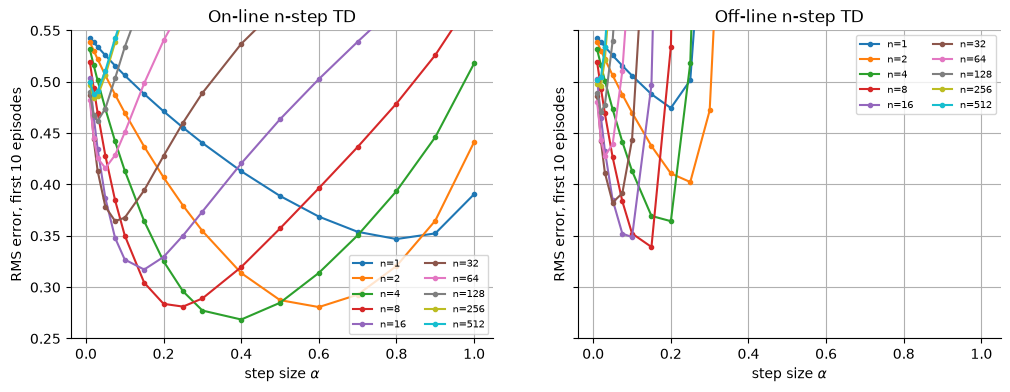

In [10]:
n_on = run(walks, lambda V, ep: n_step_episode(V, ep, NS, ALPHAS, True), len(NS))
n_off = run(walks, lambda V, ep: n_step_episode(V, ep, NS, ALPHAS, False), len(NS))
best_table("On-line n-step TD", n_on, [f"n={n}" for n in NS])
best_table("Off-line n-step TD", n_off, [f"n={n}" for n in NS])
gap_on_off = best_alpha(n_off)[1].mean(axis=0) - best_alpha(n_on)[1].mean(axis=0)
print("Best off-line minus best on-line error for n = 1..512:", [round(float(g), 4) for g in gap_on_off])
gain = best_alpha(n_off)[1] - best_alpha(n_on)[1]
z_on_off_n = gain.mean(axis=0) / (gain.std(axis=0, ddof=1) / np.sqrt(N_REPS))
z_limit_on_off = stats.norm.isf(FAMILY_ALPHA / len(NS))
print("Paired z of that difference for each n:", [round(float(z), 1) for z in z_on_off_n], f"(one-sided limit {z_limit_on_off:.2f} for {len(NS)} comparisons)")
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE, sharey=True)
error_plot(axes[0], n_on, [f"n={n}" for n in NS], "On-line n-step TD")
error_plot(axes[1], n_off, [f"n={n}" for n in NS], "Off-line n-step TD")
plt.show()

### Reading the result

- **Intermediate $n$ is best.** On-line, one-step TD ($n$ = 1) reaches 0.3469 at $\alpha$ = 0.80 and $n$ = 4 reaches 0.2685 at $\alpha$ = 0.40, with $n$ = 2 (0.2806) and $n$ = 8 (0.2811) close behind; the error rises again with larger $n$ to 0.4882 at $n$ = 512 (best $\alpha$ 0.02). Off-line, $n$ = 1 reaches 0.4745, $n$ = 8 reaches 0.3392 ($\alpha$ = 0.15) and $n$ = 512 reaches 0.5016 (at the grid's lower edge, $\alpha$ = 0.01). The standard errors are between 0.0021 and 0.0112; the paired differences are in the side-by-side section.
- **The best step size shrinks as $n$ grows**, from 0.80 at $n$ = 1 to 0.02 at $n$ = 512 on-line, and from 0.20 to 0.01 off-line. A longer return carries more noise from the extra random rewards, so smaller steps are needed; this explanation is not tested here.
- **On-line is better than off-line for every $n$.** The best off-line error minus the best on-line error is 0.1276 at $n$ = 1, 0.0958 at $n$ = 4, 0.0316 at $n$ = 16, and at most 0.0134 for $n$ of 64 or more (smallest, 0.0088, at $n$ = 128). Its paired $z$ score (the difference over its paired standard error) is 44.1, 10.5, 10.2, 10.1, 10.9, 11.9, 7.3, 7.6, 11.7 and 6.1 for $n$ = 1 to 512, all above the one-sided Bonferroni limit 2.58 for ten comparisons. The gap is largest at small $n$.
- **Off-line curves turn up early.** The first step size with error above the start's 0.5477 is 0.3 at $n$ = 1, 0.4 at $n$ = 2, 0.3 at $n$ = 4, 0.25 at $n$ = 8 and smaller for larger $n$ (0.05 at $n$ = 256 and 512). On-line the error stays below the start's at every grid step size up to 1.0 for $n$ = 1, 2 and 4, and first exceeds it at 1.0 for $n$ = 8, 0.8 for $n$ = 16, 0.5 for $n$ = 32 and 0.1 for $n$ = 256 and 512. For $n$ of 1 to 4 this is consistent with the book's remark that the off-line methods are unstable for $\alpha$ much above 0.3; for larger $n$ they leave the useful range much sooner. Why off-line updating is worse is an explanation not tested here: all increments of an episode use the same old values, so a state visited many times receives many full-size increments.
- **Against the book's figure (by eye):** similar. The curves have the same shapes: U-shaped, the minimum moving to smaller $\alpha$ with larger $n$, on-line curves lower and wider than off-line ones, off-line curves leaving the plotted range at small step sizes (the book's off-line panels end at $\alpha$ = 0.3, and the curves for larger $n$ leave them well before that, as here). The numerical minima were not read off the book's plot.

## 4. The $\lambda$-return and its forward-view algorithm

Instead of one $n$, average all the $n$-step returns. The **$\lambda$-return** weights the $n$-step return by $(1 - \lambda)\lambda^{n-1}$, and the complete return takes all the weight that would fall after the end of the episode:

$$
L_t = (1 - \lambda) \sum_{n=1}^{T-t-1} \lambda^{n-1} G_t^{t+n}\big(V_t(S_{t+n})\big) + \lambda^{T-t-1} G_t,
\qquad \Delta_t(S_t) = \alpha \big[ L_t - V_t(S_t) \big]
$$

- $T$ is the last time step, $\lambda \in [0, 1]$ is the trace-decay parameter. The weights are positive and sum to 1. Worked example: $\lambda$ = 0.5 with three steps left gives weights 0.5, 0.25 and 0.25.
- $\lambda = 0$ leaves only the one-step return (TD(0)); $\lambda = 1$ leaves only $G_t$ (constant-$\alpha$ MC). So $\lambda$ is a dial between them.
- **Forward view:** each visited state looks ahead at its future to form its target. On-line and off-line updating work as in the $n$-step section, and on-line again uses $V_t$ in the whole return.
- **Implementation:** the definition costs a sum over $n$ for each $t$. With the values held fixed the return obeys $L_t = R_{t+1} + \gamma[(1 - \lambda) V(S_{t+1}) + \lambda L_{t+1}]$, so $L_t = \text{ret}_t + \sum_s w_t(s) V(s)$, where the reward part $\text{ret}_t$ and the weights $w_t(s)$ on the values depend only on the walk and are computed once per episode by a backward recursion; each step then costs one inner product. The recursion is checked against the explicit weighted average of $n$-step returns, which uses neither the recursion nor the weights.

In [11]:
def lambda_weights(lam: float, steps_left: int) -> np.ndarray:
    """Weights of the 1-step, ..., (steps_left - 1)-step returns, then of the complete return, in the lambda-return."""
    n = np.arange(1, steps_left)
    return np.append((1 - lam) * lam ** (n - 1.0), lam ** (steps_left - 1.0))


def lambda_return_explicit(
    rew: np.ndarray, states: np.ndarray, v: np.ndarray, t: int, lam: float, gamma: float = GAMMA
) -> float:
    """L_t of one episode as the weighted average of its n-step returns (the definition)."""
    left = len(rew) - t
    returns = [n_step_return(rew, states, v, t, n, gamma) for n in range(1, left + 1)]
    return float(lambda_weights(lam, left) @ returns)


def lambda_terms(ep: Episode, lams: np.ndarray, size: int, gamma: float = GAMMA) -> tuple[np.ndarray, np.ndarray]:
    """Split L_t = ret[t] + sum_s w[t, s] V(s) into the part from rewards and the weights on the values (backward recursion)."""
    R, T_max = ep.rew.shape
    w, ret = np.zeros((T_max + 1, R, size, len(lams))), np.zeros((T_max + 1, R, len(lams)))
    for t in range(T_max - 1, -1, -1):
        w[t], ret[t] = gamma * lams * w[t + 1], ep.rew[:, t, None] + gamma * lams * ret[t + 1]
        k = ep.active[t + 1]
        w[t, np.arange(k), ep.S[:k, t + 1]] += gamma * (1 - lams)
    return ret, w


def lambda_return_episode(
    V: np.ndarray, ep: Episode, lams: np.ndarray, alphas: np.ndarray, online: bool, gamma: float = GAMMA
) -> np.ndarray:
    """Forward-view lambda-return algorithm over one episode for every lambda and step size at once."""
    V, total = V.copy(), np.zeros_like(V)
    acc = V if online else total
    ret, w = lambda_terms(ep, lams, V.shape[1], gamma)
    for t in range(ep.rew.shape[1]):
        k = ep.active[t]
        r, s = np.arange(k), ep.S[:k, t]
        target = ret[t, :k, :, None] + np.einsum("rsp,rspa->rpa", w[t, :k], V[:k])
        acc[r, s] += alphas * (target - V[r, s])
    return V if online else V + total

In [12]:
rng = np.random.default_rng(SEED_LAMBDA)
weights = [lambda_weights(lam, left) for lam in LAMS for left in WEIGHT_STEPS]
weights_sum_err = max(abs(w.sum() - 1) for w in weights)
worked = lambda_weights(WORKED_LAM, WORKED_LEFT).tolist()
print(f"lambda = {WORKED_LAM}, {WORKED_LEFT} steps left, weights on the 1-step, 2-step and complete return: {worked}")
print(f"Largest |sum of weights - 1| over {len(weights)} (lambda, steps left) pairs: {weights_sum_err:.1e}")

ep_c = walk_episode(rng, CHECK_REPS)
row = int(np.abs(ep_c.T - CHECK_LEN).argmin())
T_c, v_c = int(ep_c.T[row]), np.concatenate([[0.0], rng.uniform(-1, 1, N_STATES), [0.0]])
gaps = []
for gamma in (GAMMA, GAMMA_CHECK):
    ret, w = lambda_terms(ep_c, np.array(CHECK_LAMS), N_STATES + 2, gamma)
    for p, lam in enumerate(CHECK_LAMS):
        fast = ret[:T_c, row, p] + w[:T_c, row, :, p] @ v_c
        slow = [
            lambda_return_explicit(ep_c.rew[row, :T_c], ep_c.S[row, : T_c + 1], v_c, t, lam, gamma) for t in range(T_c)
        ]
        gaps.append(np.abs(fast - slow).max())
print(
    f"Walk of {T_c} steps: largest |recursion - weighted average of n-step returns| over {len(gaps)} (gamma, lambda) pairs and all times: {max(gaps):.1e}"
)
print(
    "Checkpoint: the weights sum to 1 and the recursion equals the definition:",
    bool(weights_sum_err < EXACT_TOL and max(gaps) < EXACT_TOL),
)

lambda = 0.5, 3 steps left, weights on the 1-step, 2-step and complete return: [0.5, 0.25, 0.25]
Largest |sum of weights - 1| over 40 (lambda, steps left) pairs: 2.2e-16
Walk of 26 steps: largest |recursion - weighted average of n-step returns| over 8 (gamma, lambda) pairs and all times: 1.1e-16
Checkpoint: the weights sum to 1 and the recursion equals the definition: True


lambda = 0 equals one-step TD, and lambda = 1 equals constant-alpha MC (n = 552), at every step size, on-line and off-line: True True
On-line lambda-return: parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  0.0    0.800  0.3469 (0.0023)  none
  0.4    0.800  0.2772 (0.0050)  none
  0.8    0.400  0.2630 (0.0063)  none
  0.9    0.250  0.2879 (0.0064)  none
  0.95   0.150  0.3275 (0.0062)  none
  0.975  0.100  0.3729 (0.0063)  0.6
  0.99   0.050  0.4251 (0.0059)  0.25
  1.0    0.020  0.4884 (0.0057)  0.1
Off-line lambda-return: parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  0.0    0.200  0.4745 (0.0021)  0.3
  0.4    0.200  0.4325 (0.0029)  0.3
  0.8    0.150  0.3556 (0.0029)  0.25
  0.9    0.150  0.3383 (0.0063)  0.25
  0.95   0.100  0.3540 (0.0051)  0.2
  0.975  0.075  0.3935 (0.0057)  0.15
  0.99   0.030  0.4406 (0.0046)  0.1
  1.0    0.010  0.5018 (0.0038)  0.05


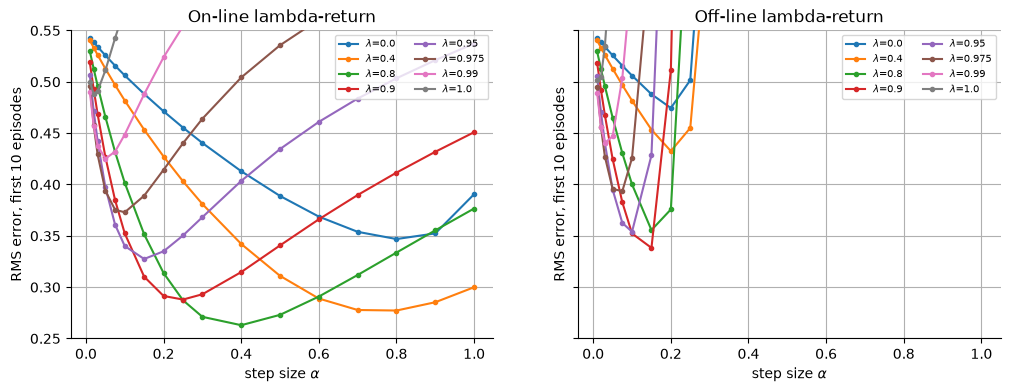

In [13]:
def same_curves(a: np.ndarray, b: np.ndarray) -> bool:
    """Do two error arrays agree to the relative tolerance REL_TOL?"""
    return bool(np.allclose(a, b, rtol=REL_TOL, atol=0))


lam_on = run(walks, lambda V, ep: lambda_return_episode(V, ep, LAMS, ALPHAS, True), len(LAMS))
lam_off = run(walks, lambda V, ep: lambda_return_episode(V, ep, LAMS, ALPHAS, False), len(LAMS))
longest = int(lengths.max())
mc_on = run(walks, lambda V, ep: n_step_episode(V, ep, np.array([longest]), ALPHAS, True), 1)
mc_off = run(walks, lambda V, ep: n_step_episode(V, ep, np.array([longest]), ALPHAS, False), 1)
ok_zero = same_curves(lam_on[:, 0], n_on[:, 0]) and same_curves(lam_off[:, 0], n_off[:, 0])
ok_one = same_curves(lam_on[:, -1], mc_on[:, 0]) and same_curves(lam_off[:, -1], mc_off[:, 0])
print(
    f"lambda = 0 equals one-step TD, and lambda = 1 equals constant-alpha MC (n = {longest}), at every step size, on-line and off-line:",
    ok_zero,
    ok_one,
)
best_table("On-line lambda-return", lam_on, LAMS)
best_table("Off-line lambda-return", lam_off, LAMS)
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE, sharey=True)
error_plot(axes[0], lam_on, [f"$\\lambda$={x}" for x in LAMS], "On-line lambda-return")
error_plot(axes[1], lam_off, [f"$\\lambda$={x}" for x in LAMS], "Off-line lambda-return")
plt.show()

### Reading the result

- **The weights:** with $\lambda$ = 0.5 and three steps left they are 0.5, 0.25 and 0.25, as in the worked example. Over 40 combinations of $\lambda$ (all eight of the experiment) and steps left (1, 2, 3, 7 and 50) the largest deviation of the sum from 1 is 2.2e-16.
- **The recursion is the definition:** on a 26-step walk with random values, for four $\lambda$ at $\gamma$ = 1 and $\gamma$ = 0.9 (8 pairs), the recursion and the explicit weighted average of $n$-step returns agree to 1.1e-16 at every time step.
- **The two ends:** the on-line and off-line error curves of $\lambda$ = 0 equal those of one-step TD, and those of $\lambda$ = 1 equal those of $n$ = 552 (longer than the longest of the 1,000 walks, 552 steps, so constant-$\alpha$ MC; $n$ = 512 of the previous section is shorter than that walk and so only almost Monte Carlo), for every step size and repetition. The tolerance is a relative 1e-8: the two code paths differ by rounding of about 1e-16 per operation over about a thousand chained updates, while the wrong variant (off-line instead of on-line) would differ by 0.1 or more at the best step size of $n$ = 1 (the $n$-step experiment).
- **Intermediate $\lambda$ is best.** On-line, $\lambda$ = 0 reaches 0.3469, $\lambda$ = 0.8 reaches 0.2630 ($\alpha$ = 0.40) and $\lambda$ = 1 reaches 0.4884 ($\alpha$ = 0.02). Off-line, $\lambda$ = 0 reaches 0.4745, $\lambda$ = 0.9 reaches 0.3383 ($\alpha$ = 0.15) and $\lambda$ = 1 reaches 0.5018 (at the grid's lower edge, $\alpha$ = 0.01).
- **Comparable with the $n$-step methods:** the best on-line error is 0.2630 against 0.2685 for $n$-step, and the best off-line error is 0.3383 against 0.3392 (paired differences in the side-by-side section).
- **Off-line curves turn up early again.** Off-line, the first step size above the start's error is 0.3 at $\lambda$ = 0 and 0.4, 0.25 at 0.8 and 0.9, 0.2 at 0.95, and 0.15, 0.1 and 0.05 at $\lambda$ = 0.975, 0.99 and 1. On-line the error stays below the start's over the whole grid for $\lambda$ up to 0.95; it first exceeds it at $\alpha$ = 0.6 for $\lambda$ = 0.975, 0.25 for 0.99 and 0.1 for $\lambda$ = 1.
- **Against the book's figure (by eye):** the upper row of the book's six-panel figure shows the same pattern: on-line curves lower and wider, off-line curves leaving the plotted range at small step sizes, intermediate $\lambda$ best. The book labels its off-line panel as equal to off-line TD($\lambda$) with accumulating traces, which the next section confirms numerically.

## 5. TD($\lambda$): the backward view with eligibility traces

The $\lambda$-return looks into the future; TD($\lambda$) gets the same effect causally. At every step it computes the one-step TD error and sends it back to all earlier states in proportion to an **eligibility trace** $E_t(s)$, a per-state memory of how recently and often the state was visited:

$$
\delta_t = R_{t+1} + \gamma V_t(S_{t+1}) - V_t(S_t), \qquad \Delta V_t(s) = \alpha\, \delta_t\, E_t(s) \;\;\forall s
$$

$$
E_t(s) = \gamma\lambda E_{t-1}(s) \;\; (s \neq S_t), \qquad E_t(S_t) = \begin{cases} \gamma\lambda E_{t-1}(S_t) + 1 & \text{accumulating} \\ 1 & \text{replacing} \\ (1 - \alpha)\gamma\lambda E_{t-1}(S_t) + 1 & \text{dutch} \end{cases}
$$

- Traces start at 0 in each episode. In the algorithm the visited state's trace is incremented, then every state moves by $\alpha\delta E$, then every trace decays by $\gamma\lambda$. Updating is on-line or off-line as before; off-line, the $\delta_t$ use the old values.
- At $\lambda = 0$ only the visited state has a nonzero trace, so the method is exactly TD(0).
- The three kinds differ only in the visited state's increment. Dutch traces interpolate: $\alpha \to 0$ gives accumulating and $\alpha = 1$ gives replacing.
- **What the chapter claims about forward and backward views:** off-line with accumulating traces they produce the same total change for every $\lambda$; on-line they differ for $\lambda > 0$ but are close for small $\alpha$; dutch traces come closer; at $\lambda = 0$ they coincide. These are checked below with random starting values (so the check does not depend on the all-zero start), one episode, 40 walks, and, for the off-line claim, also at $\gamma$ = 0.9.
- **Independent routes:** the off-line backward change is compared with the forward change from the $\lambda$-return code and, for one walk, with a forward change computed from the definition (weighted $n$-step returns). Constant-$\alpha$ MC is a separate implementation from the reversed reward sum.
- **Terms:** a log-log slope is the slope of the logarithm of the difference against the logarithm of $\alpha$; a difference proportional to $\alpha^2$ ("second order in $\alpha$") has slope 2, so cutting $\alpha$ tenfold cuts it a hundredfold.

In [14]:
def bump(e: np.ndarray, alpha: np.ndarray | float, kind: str) -> np.ndarray:
    """Trace of the visited state after the visit: accumulating adds 1, replacing resets to 1, dutch is in between."""
    if kind == "accumulating":
        return e + 1
    if kind == "replacing":
        return np.ones_like(e)
    return (1 - alpha) * e + 1


def td_lambda_episode(
    V: np.ndarray, ep: Episode, lams: np.ndarray, alphas: np.ndarray, kind: str, online: bool, gamma: float = GAMMA
) -> np.ndarray:
    """Backward-view TD(lambda) over one episode: every state moves by alpha * delta_t * E_t(s)."""
    V, total, E = V.copy(), np.zeros_like(V), np.zeros_like(V)
    acc, decay = (V if online else total), gamma * lams[:, None]
    for t in range(ep.rew.shape[1]):
        k = ep.active[t]
        r, s, s2 = np.arange(k), ep.S[:k, t], ep.S[:k, t + 1]
        delta = ep.rew[:k, t, None, None] + gamma * V[r, s2] - V[r, s]
        E[r, s] = bump(E[r, s], alphas, kind)
        acc[:k] += alphas * delta[:, None] * E[:k]
        E[:k] *= decay
    return V if online else V + total


def mc_episode(V: np.ndarray, ep: Episode, alphas: np.ndarray, online: bool, gamma: float = GAMMA) -> np.ndarray:
    """Constant-alpha Monte Carlo over one episode: S_t moves toward the complete return G_t, the same for every parameter column."""
    V, total = V.copy(), np.zeros_like(V)
    acc, G = (V if online else total), np.zeros((ep.rew.shape[1] + 1, ep.rew.shape[0]))
    for t in range(ep.rew.shape[1] - 1, -1, -1):
        G[t] = ep.rew[:, t] + gamma * G[t + 1]
    for t in range(ep.rew.shape[1]):
        k = ep.active[t]
        r, s = np.arange(k), ep.S[:k, t]
        acc[r, s] += alphas * (G[t, :k, None, None] - V[r, s])
    return V if online else V + total

Largest trace value with gamma * lambda = 0.8, visits at (2, 3, 8, 11, 12, 13, 14) and dutch alpha = 0.5:
{'accumulating': 3.3688, 'dutch': 1.6441, 'replacing': 1.0}


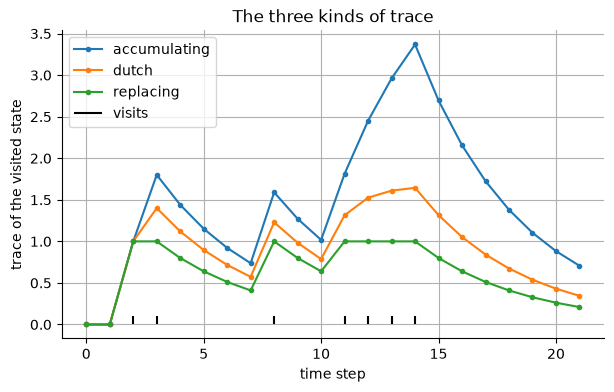

Five-state episode, TD(lambda) with accumulating traces: change of V(C), V(D), V(E)
  lambda = 0.0: backward [0.0, 0.0, 0.05], forward [0.0, 0.0, 0.05]
  lambda = 0.8: backward [0.032, 0.04, 0.05], forward [0.032, 0.04, 0.05]
  lambda = 1.0: backward [0.05, 0.05, 0.05], forward [0.05, 0.05, 0.05]
  values after the episode at lambda = 0.8: [0.532, 0.54, 0.55]; traces of C, D, E at the last step: [0.64, 0.8, 1.0]
Checkpoint: the changes equal the hand-derived alpha * delta * trace values (0.032, 0.04, 0.05 at lambda = 0.8): True


In [15]:
steps = np.arange(TRACE_STEPS)
traces = {}
for kind in ("accumulating", "dutch", "replacing"):
    e, line = 0.0, []
    for t in steps:
        e = TRACE_GL * e
        e = float(bump(np.array(e), TRACE_ALPHA, kind)) if t in TRACE_VISITS else e
        line.append(e)
    traces[kind] = np.array(line)
print(
    f"Largest trace value with gamma * lambda = {TRACE_GL}, visits at {TRACE_VISITS} and dutch alpha = {TRACE_ALPHA}:"
)
print({kind: round(float(line.max()), 4) for kind, line in traces.items()})
fig, ax = plt.subplots()
for kind, line in traces.items():
    ax.plot(steps, line, marker=".", label=kind)
ax.vlines(TRACE_VISITS, 0, TRACE_TICK, color="k", label="visits")
ax.set(xlabel="time step", ylabel="trace of the visited state", title="The three kinds of trace")
ax.legend()
plt.show()

lams5 = np.array([0.0, EX_LAM, 1.0])
V5l = V5[:, :, :1].repeat(len(lams5), axis=2)
change5 = td_lambda_episode(V5l, five, lams5, alpha_ex, "accumulating", True)[0, 3:6, :, 0].T - EX_V0
forward5 = lambda_return_episode(V5l, five, lams5, alpha_ex, True)[0, 3:6, :, 0].T - EX_V0
by_hand = np.array([[0.0, 0.0, 0.05], [0.032, 0.04, 0.05], [0.05, 0.05, 0.05]])
print("Five-state episode, TD(lambda) with accumulating traces: change of V(C), V(D), V(E)")
for lam, a, f in zip(lams5, change5, forward5):
    print(f"  lambda = {lam}: backward {np.round(a, 4).tolist()}, forward {np.round(f, 4).tolist()}")
trace = np.zeros(3)
for t in range(3):
    trace = EX_LAM * trace
    trace[t] = bump(trace[t], EX_ALPHA, "accumulating")
print(f"  values after the episode at lambda = {EX_LAM}: {np.round(EX_V0 + change5[1], 4).tolist()}; traces of C, D, E at the last step: {np.round(trace, 4).tolist()}")
five_td_ok = bool(np.abs(change5 - by_hand).max() < EXACT_TOL and np.abs(forward5 - by_hand).max() < EXACT_TOL)
print(
    "Checkpoint: the changes equal the hand-derived alpha * delta * trace values (0.032, 0.04, 0.05 at lambda = 0.8):",
    five_td_ok,
)

### Reading the result: traces and the five-state episode

- With visits at the times in the picture, $\gamma\lambda$ = 0.8 and four visits in consecutive steps at the end, the largest trace is 3.3688 for accumulating traces, 1.6441 for dutch traces ($\alpha$ = 0.5) and 1.0 for replacing traces. Accumulating traces keep adding, dutch traces add less the larger $\alpha$ is, replacing traces never exceed 1. In the plot all three decay by the factor 0.8 per step between visits.
- On the five-state episode, TD($\lambda$) at $\lambda$ = 0.8 and $\alpha$ = 0.1 changes $V$(C), $V$(D) and $V$(E) by 0.032, 0.04 and 0.05, so they end at 0.532, 0.54 and 0.55: the traces of E, D and C at the last step are 1, 0.8 and 0.64, times $\alpha\delta$ = 0.05. $\lambda$ = 0 changes only E and $\lambda$ = 1 changes all three by 0.05 (with $\gamma$ = 1), as the chapter says. The forward view gives the same numbers.

In [16]:
rngs = [np.random.default_rng(c) for c in np.random.SeedSequence(SEED_EQUIV).spawn(3)]
ep_e, lams_e = walk_episode(rngs[0], CHECK_REPS), np.array(CHECK_LAMS)
alphas_e, alphas_o = np.array(CHECK_ALPHAS), np.array(ONLINE_ALPHAS)
V_e = rngs[1].uniform(-1, 1, (CHECK_REPS, N_STATES + 2, len(lams_e), len(alphas_e)))
V_e[:, [0, N_STATES + 1]] = 0
row = int(np.abs(ep_e.T - CHECK_LEN).argmin())
T_e = int(ep_e.T[row])
off_gap, explicit_gap = {}, []
for gamma in (GAMMA, GAMMA_CHECK):
    fwd = lambda_return_episode(V_e, ep_e, lams_e, alphas_e, False, gamma) - V_e
    bwd = td_lambda_episode(V_e, ep_e, lams_e, alphas_e, "accumulating", False, gamma) - V_e
    off_gap[gamma] = (np.abs(fwd - bwd).max(), np.abs(fwd).max())
    for p, lam in enumerate(lams_e):
        for a, alpha in enumerate(alphas_e):
            v, change = V_e[row, :, p, a], np.zeros(N_STATES + 2)
            for t in range(T_e):
                target = lambda_return_explicit(ep_e.rew[row, :T_e], ep_e.S[row, : T_e + 1], v, t, lam, gamma)
                change[ep_e.S[row, t]] += alpha * (target - v[ep_e.S[row, t]])
            explicit_gap.append(np.abs(change - fwd[row, :, p, a]).max())
for gamma, (g_off, size) in off_gap.items():
    print(
        f"Off-line, accumulating, gamma = {gamma}: largest |forward - backward| change {g_off:.1e} (largest change {size:.3f}) over {CHECK_REPS} walks, {len(lams_e)} lambdas, {len(alphas_e)} step sizes"
    )
print(
    f"Forward change recomputed from the definition on one {T_e}-step walk: largest difference {max(explicit_gap):.1e}"
)
print(
    "Checkpoint: off-line accumulating TD(lambda) and the lambda-return algorithm give the same total change:",
    bool(max(g for g, _ in off_gap.values()) < EXACT_TOL and max(explicit_gap) < EXACT_TOL),
)

Off-line, accumulating, gamma = 1.0: largest |forward - backward| change 5.0e-14 (largest change 61.237) over 40 walks, 4 lambdas, 3 step sizes
Off-line, accumulating, gamma = 0.9: largest |forward - backward| change 2.5e-14 (largest change 47.095) over 40 walks, 4 lambdas, 3 step sizes
Forward change recomputed from the definition on one 22-step walk: largest difference 8.9e-16
Checkpoint: off-line accumulating TD(lambda) and the lambda-return algorithm give the same total change: True


In [17]:
def end_gap(V0: np.ndarray, ep: Episode, lams: np.ndarray, alphas: np.ndarray, kind: str) -> np.ndarray:
    """Largest |on-line TD(lambda) with trace `kind` - on-line lambda-return algorithm| after one episode, per (lambda, step size)."""
    other = lambda_return_episode(V0, ep, lams, alphas, True)
    return np.abs(td_lambda_episode(V0, ep, lams, alphas, kind, True) - other).max(axis=(0, 1))


V_o = rngs[2].uniform(-1, 1, (CHECK_REPS, N_STATES + 2, len(lams_e), len(alphas_o)))
V_o[:, [0, N_STATES + 1]] = 0
gap_on = {kind: end_gap(V_o, ep_e, lams_e, alphas_o, kind) for kind in ("accumulating", "dutch", "replacing")}
print("On-line, largest |TD(lambda) - lambda-return| after one episode; per lambda, columns alpha =", ONLINE_ALPHAS)
for kind, g in gap_on.items():
    print(f"  {kind}:", {lam: np.round(line, 4).tolist() for lam, line in zip(CHECK_LAMS, g)})
g_acc, g_dutch, g_repl = (np.round(gap_on[k][1:], 4) for k in ("accumulating", "dutch", "replacing"))
print(f"Over the {g_acc.size} cells with lambda > 0 (4 decimals): dutch closer than accumulating in {int((g_dutch < g_acc).sum())}, equal in {int((g_dutch == g_acc).sum())}, farther in {int((g_dutch > g_acc).sum())}; replacing farther in {int((g_repl > g_acc).sum())}")

On-line, largest |TD(lambda) - lambda-return| after one episode; per lambda, columns alpha = (0.01, 0.05, 0.1)
  accumulating: {0.0: [0.0, 0.0, 0.0], 0.5: [0.0008, 0.0128, 0.025], 0.9: [0.007, 0.136, 0.2104], 1.0: [0.2371, 1.2903, 3.118]}
  dutch: {0.0: [0.0, 0.0, 0.0], 0.5: [0.0008, 0.0097, 0.0255], 0.9: [0.0044, 0.0644, 0.1612], 1.0: [0.1404, 1.1278, 0.7461]}
  replacing: {0.0: [0.0, 0.0, 0.0], 0.5: [0.0438, 0.0819, 0.0878], 0.9: [0.1632, 0.4775, 0.5382], 1.0: [0.5542, 1.4667, 1.7703]}
Over the 9 cells with lambda > 0 (4 decimals): dutch closer than accumulating in 7, equal in 1, farther in 1; replacing farther in 8


In [18]:
V_s = np.repeat(rngs[2].uniform(-1, 1, (CHECK_REPS, N_STATES + 2, 1, 1)), len(SMALL_ALPHAS), axis=3)
V_s[:, [0, N_STATES + 1]] = 0
small = end_gap(V_s, ep_e, np.array([SMALL_LAM]), SMALL_ALPHAS, "accumulating")[0]
slope = np.polyfit(np.log(SMALL_ALPHAS), np.log(small), 1)[0]
print(f"Small step sizes, lambda = {SMALL_LAM}: alpha {SMALL_ALPHAS.tolist()}")
print(f"  largest on-line difference {[float(f'{g:.2e}') for g in small]}")
print(
    f"  divided by alpha^2: {[round(float(g / a**2), 1) for g, a in zip(small, SMALL_ALPHAS)]}; fitted log-log slope {slope:.3f}"
)
mc_gap_off = np.abs(
    td_lambda_episode(V_e[:, :, :1], ep_e, LAM_ONE, alphas_e, "accumulating", False)
    - mc_episode(V_e[:, :, :1], ep_e, alphas_e, False)
).max()
mc_gap_on = np.abs(
    td_lambda_episode(V_o[:, :, :1], ep_e, LAM_ONE, alphas_o, "accumulating", True)
    - mc_episode(V_o[:, :, :1], ep_e, alphas_o, True)
).max()
print(
    f"lambda = 1, accumulating: largest |TD(1) - constant-alpha MC| after one episode: off-line {mc_gap_off:.1e}, on-line {mc_gap_on:.3f}"
)
print(
    "Checkpoint: at lambda = 0 on-line TD(0) and the on-line lambda-return are identical for every trace kind:",
    bool(max(g[0].max() for g in gap_on.values()) < EXACT_TOL),
)
print(
    f"Checkpoint: the on-line difference is second order in alpha (slope within {SLOPE_TOL} of 2):",
    bool(abs(slope - 2) < SLOPE_TOL),
)
print(
    "Checkpoint: off-line TD(1) with accumulating traces equals off-line constant-alpha MC:",
    bool(mc_gap_off < EXACT_TOL),
)

Small step sizes, lambda = 0.9: alpha [1e-05, 3e-05, 0.0001, 0.0003, 0.001]
  largest on-line difference [8.34e-09, 7.51e-08, 8.33e-07, 7.47e-06, 8.19e-05]
  divided by alpha^2: [83.4, 83.4, 83.3, 83.0, 81.9]; fitted log-log slope 1.996
lambda = 1, accumulating: largest |TD(1) - constant-alpha MC| after one episode: off-line 2.1e-14, on-line 3.594
Checkpoint: at lambda = 0 on-line TD(0) and the on-line lambda-return are identical for every trace kind: True
Checkpoint: the on-line difference is second order in alpha (slope within 0.2 of 2): True
Checkpoint: off-line TD(1) with accumulating traces equals off-line constant-alpha MC: True


### Reading the result: forward and backward views

**Equal (to rounding):**
- **Off-line, accumulating traces, every $\lambda$ and $\alpha$ tried.** The total change over an episode from the forward $\lambda$-return algorithm and from backward TD($\lambda$) differ by at most 5.0e-14 at $\gamma$ = 1 and 2.5e-14 at $\gamma$ = 0.9, while the changes themselves reach 61.237 and 47.095 (random start values, $\lambda$ in 0, 0.5, 0.9, 1, $\alpha$ in 0.1, 0.5, 1). The large step size is included on purpose: the equality is exact, not a small-$\alpha$ approximation. A forward change computed from the definition alone (weighted $n$-step returns, a 22-step walk, both $\gamma$, all 12 settings of $\lambda$ and $\alpha$) differs from the code's by at most 8.9e-16. Because the values do not move during an off-line episode, equal totals mean equal values after the episode; the chapter's further claim that the two agree at every step inside the episode is not separately tested.
- **At $\lambda$ = 0 on-line,** all three trace kinds and the $\lambda$-return algorithm give identical values after an episode at every step size (difference 0.0).
- **At $\lambda$ = 1 off-line,** TD(1) equals off-line constant-$\alpha$ MC (2.1e-14).

**Not equal:**
- **On-line with accumulating traces, $\lambda > 0$.** After one episode the largest difference from the on-line $\lambda$-return algorithm is 0.0008, 0.0128 and 0.025 at $\lambda$ = 0.5 for $\alpha$ = 0.01, 0.05 and 0.1; 0.007, 0.136 and 0.2104 at $\lambda$ = 0.9; 0.2371, 1.2903 and 3.118 at $\lambda$ = 1. It grows with both $\lambda$ and $\alpha$.
- **Small step sizes:** at $\lambda$ = 0.9 and $\alpha$ from 1e-5 to 1e-3 (the same random start values at every $\alpha$) the difference grows from 8.34e-09 to 8.19e-05; divided by $\alpha^2$ it stays between 81.9 and 83.4, and the fitted log-log slope is 1.996. The first-order terms agree and the difference is second order in $\alpha$, so the two are close for small $\alpha$, as the chapter says. The constant is large; that this is why $\alpha$ must be small for the two to agree is an explanation, not tested here.
- **Dutch traces** are closer than accumulating ones in 7 of the 9 cells with $\lambda$ > 0 (for example 0.0044 against 0.007, 0.0644 against 0.136 and 0.1612 against 0.2104 at $\lambda$ = 0.9), equal at $\lambda$ = 0.5, $\alpha$ = 0.01 (0.0008 each) and slightly farther at $\lambda$ = 0.5, $\alpha$ = 0.1 (0.0255 against 0.025). They are not exact. Replacing traces are farther from the on-line $\lambda$-return than accumulating ones in 8 of the 9 cells (for example 0.0438 against 0.0008 at $\lambda$ = 0.5, $\alpha$ = 0.01); they are not meant to approximate it.
- **On-line TD(1) with accumulating traces is not constant-$\alpha$ MC:** the largest difference after an episode is 3.594 at step sizes 0.01, 0.05 and 0.1, though off-line they are equal.

The second-order tolerance (slope within 0.2 of 2) is derived: the first-order terms cancel, so the leading difference is proportional to $\alpha^2$, and for $\alpha$ at most 1e-3 and episodes of tens of steps the next-order terms change the fitted slope by roughly $\alpha$ times the episode length, a few hundredths.

Cells where the mean error is diverged (at least 50): TD(lambda) 2395, lambda-return 2395, in one but not the other 0, of 13600
Largest relative difference of off-line TD(lambda) and off-line lambda-return in the RMS error over the 11205 other cells: 8.8e-15
Accumulating traces, lambda = 0.95, alpha = 0.4: repetitions above the start's error 97 of 100, median 0.6746, above 1: 4
Largest |on-line TD(0), any trace kind - on-line one-step n-step TD| over step sizes and repetitions: 0.0e+00
On-line TD(lambda), accumulating traces: parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  0.0    0.800  0.3469 (0.0023)  none
  0.4    0.700  0.2761 (0.0049)  none
  0.8    0.300  0.2677 (0.0058)  0.9
  0.9    0.200  0.2957 (0.0059)  0.6
  0.95   0.100  0.3394 (0.0050)  0.4
  0.975  0.075  0.3818 (0.0055)  0.2
  0.99   0.030  0.4381 (0.0045)  0.1
  1.0    0.010  0.5011 (0.0038)  0.05
On-line TD(lambda), replacing traces: parameter, best alpha, RMS error (stand

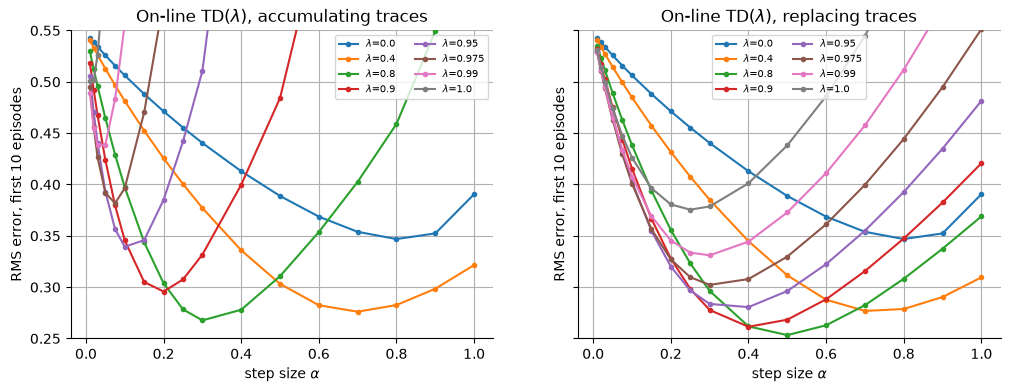

In [19]:
kinds = ("accumulating", "replacing", "dutch")
td_on = {k: run(walks, lambda V, ep, k=k: td_lambda_episode(V, ep, LAMS, ALPHAS, k, True), len(LAMS)) for k in kinds}
td_off = run(walks, lambda V, ep: td_lambda_episode(V, ep, LAMS, ALPHAS, "accumulating", False), len(LAMS))
div_td, div_lam = td_off >= DIVERGED, lam_off >= DIVERGED
finite = ~(div_td | div_lam)
off_gap_curves = (np.abs(td_off - lam_off) / lam_off)[finite].max()
same_zero = max(np.abs(td_on[k][:, 0] - n_on[:, 0]).max() for k in kinds)
print(f"Cells where the mean error is diverged (at least {DIVERGED:g}): TD(lambda) {int(div_td.sum())}, lambda-return {int(div_lam.sum())}, in one but not the other {int((div_td != div_lam).sum())}, of {div_td.size}")
print(
    f"Largest relative difference of off-line TD(lambda) and off-line lambda-return in the RMS error over the {int(finite.sum())} other cells: {off_gap_curves:.1e}"
)
probe = td_on["accumulating"][:, LAMS == LAM_PROBE, ALPHAS == ALPHA_PROBE].ravel()
print(f"Accumulating traces, lambda = {LAM_PROBE}, alpha = {ALPHA_PROBE}: repetitions above the start's error {int((probe > initial_error).sum())} of {N_REPS}, median {np.median(probe):.4f}, above {LARGE_ERR:g}: {int((probe > LARGE_ERR).sum())}")
print(
    f"Largest |on-line TD(0), any trace kind - on-line one-step n-step TD| over step sizes and repetitions: {same_zero:.1e}"
)
for k in kinds:
    best_table(f"On-line TD(lambda), {k} traces", td_on[k], LAMS)
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE, sharey=True)
error_plot(
    axes[0], td_on["accumulating"], [f"$\\lambda$={x}" for x in LAMS], "On-line TD($\\lambda$), accumulating traces"
)
error_plot(axes[1], td_on["replacing"], [f"$\\lambda$={x}" for x in LAMS], "On-line TD($\\lambda$), replacing traces")
plt.show()

### Reading the result: the random-walk experiment

- **Off-line TD($\lambda$) is the off-line $\lambda$-return algorithm on the whole experiment:** the RMS error curves agree to a relative 8.8e-15 over all 11,205 cells whose runs did not diverge, so the book's upper-right panel is one set of curves for both. The other 2,395 of the 13,600 cells are diverged (mean error at least 50) for both methods, and for none of them in one method only.
- **At $\lambda$ = 0** all trace kinds are the same algorithm as one-step TD: the largest difference in the RMS error over every step size and repetition is 0.
- **Intermediate $\lambda$ is best for every trace kind.** Accumulating traces: 0.3469 at $\lambda$ = 0, 0.2677 at $\lambda$ = 0.8 ($\alpha$ = 0.3) and 0.5011 at $\lambda$ = 1 ($\alpha$ = 0.01). Replacing: 0.2533 at $\lambda$ = 0.8 ($\alpha$ = 0.5) and 0.3755 at $\lambda$ = 1 ($\alpha$ = 0.25). Dutch: 0.2581 at $\lambda$ = 0.8 and 0.4854 at $\lambda$ = 1.
- **Accumulating traces leave the useful range early when $\lambda$ is large.** The first step size at which the error exceeds the start's 0.5477 is 0.9 at $\lambda$ = 0.8, 0.6 at 0.9, 0.4 at 0.95, 0.2 at 0.975, 0.1 at 0.99 and 0.05 at $\lambda$ = 1. For replacing traces there is none up to $\lambda$ = 0.95, then 1.0, 0.9 and 0.8 at 0.975, 0.99 and 1; for dutch traces none up to 0.95, then 1.0, 0.6 and 0.15. This is the ordering of the chapter's warning that accumulating traces are unstable for large $\lambda$ and $\alpha$. This agrees by eye with the book's accumulating panel, where the $\lambda$ = 0.95 curve leaves the plotted range at about $\alpha$ = 0.35 and the $\lambda$ = 0.9 curve at about 0.55; the text's "about $\lambda > 0.9$, $\alpha > 0.5$" is a rough example. The score cap is not the cause: at $\lambda$ = 0.95 and $\alpha$ = 0.4, 97 of 100 repetitions are above 0.5477, their median is 0.6746 and only 4 are above 1.
- **Against the book's figure (by eye):** the accumulating panel has curves that shoot up steeply for $\lambda$ near 1, while the replacing panel has broad curves that stay low over a wide range of $\alpha$, as in the book.

## 6. True online TD($\lambda$)

On-line TD($\lambda$) only approximates the on-line $\lambda$-return. True online TD($\lambda$) adds two correction terms built from how the visited state's own value changed in the previous step, and uses the dutch trace:

$$
V_{t+1}(s) = V_t(s) + \alpha \big[ \delta_t + V_t(S_t) - V_{t-1}(S_t) \big] E_t(s) - \alpha I_{s S_t} \big[ V_t(S_t) - V_{t-1}(S_t) \big]
$$

- $I_{s S_t}$ is 1 if $s = S_t$ and 0 otherwise. The code follows the chapter's algorithm: $\Delta \leftarrow V(S) - V_{old}$, $V_{old} \leftarrow V(S')$, the dutch trace, the update of all states with $\delta + \Delta$, then $V(S) \leftarrow V(S) - \alpha\Delta$.
- **Deviation (harmless):** the printed algorithm sets $V_{old}$ to 0 once, before the first episode; the code sets it to $V(S_0)$ at the start of each episode so that the first correction is zero, as the equation requires ($V_{-1}(S_0) = V_0(S_0)$). The two give the same values, because $V$ of the terminal state is 0: after an episode $V_{old} \leftarrow V(S')$ is already 0, so the printed box also starts every later episode with $V_{old}$ = 0. The parameter `v_old_zero` runs that variant, and the check below shows that the values are identical.
- **Claim to check:** with $\lambda = 1$ the chapter says the method equals constant-$\alpha$ MC by the end of the episode. Two MC variants exist: updating $S_t$ in time order with the current value (on-line), or summing the increments of the episode with the old values (off-line). They differ when a state is revisited; both are computed.
- **Not available:** the real-time $\lambda$-return this method is equivalent to (see the title cell), so the comparison is with the on-line $\lambda$-return of the $\lambda$-return section and with dutch-trace TD($\lambda$).

In [20]:
def true_online_episode(
    V: np.ndarray, ep: Episode, lams: np.ndarray, alphas: np.ndarray, gamma: float = GAMMA, v_old_zero: bool = False
) -> np.ndarray:
    """True online TD(lambda) over one episode; v_old holds V_{t-1}(S_t) and starts at V(S_0), or at 0 as in the printed box."""
    V, E = V.copy(), np.zeros_like(V)
    v_old = np.zeros_like(V[:, 0]) if v_old_zero else V[np.arange(V.shape[0]), ep.S[:, 0]]
    decay = gamma * lams[:, None]
    for t in range(ep.rew.shape[1]):
        k = ep.active[t]
        r, s, s2 = np.arange(k), ep.S[:k, t], ep.S[:k, t + 1]
        v_s, v_s2 = V[r, s], V[r, s2]
        change, v_old[:k] = v_s - v_old[:k], v_s2
        delta = ep.rew[:k, t, None, None] + gamma * v_s2 - v_s
        E[r, s] = bump(E[r, s], alphas, "dutch")
        V[:k] += alphas * (delta + change)[:, None] * E[:k]
        E[:k] *= decay
        V[r, s] -= alphas * change
    return V

lambda = 1, step sizes (0.1, 0.5, 1.0), random start values, one episode of 40 walks: largest |true online TD(1) - MC|
  MC on-line, in time order: 7.8e-16, MC off-line, summed: 9.5e+01
  V_old = 0 at the episode start as in the printed box, against V_old = V(S_0): 7.8e-16
lambda = 0: largest |true online TD - one-step TD| in the RMS error over step sizes and repetitions: 0.0e+00
True online TD(lambda): parameter, best alpha, RMS error (standard error), first alpha with error above the start's
  0.0    0.800  0.3469 (0.0023)  none
  0.4    0.700  0.2767 (0.0047)  none
  0.8    0.400  0.2592 (0.0063)  none
  0.9    0.250  0.2819 (0.0063)  none
  0.95   0.150  0.3209 (0.0060)  none
  0.975  0.100  0.3648 (0.0061)  0.9
  0.99   0.050  0.4203 (0.0057)  0.4
  1.0    0.020  0.4884 (0.0057)  0.1


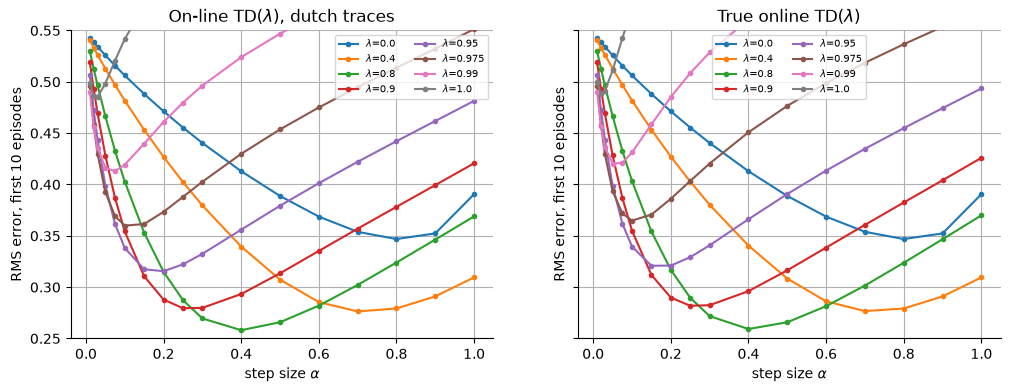

In [21]:
rngs = [np.random.default_rng(c) for c in np.random.SeedSequence(SEED_TRUE).spawn(2)]
ep_t = walk_episode(rngs[0], CHECK_REPS)
V_t = rngs[1].uniform(-1, 1, (CHECK_REPS, N_STATES + 2, 1, len(alphas_e)))
V_t[:, [0, N_STATES + 1]] = 0
true_one = true_online_episode(V_t, ep_t, LAM_ONE, alphas_e)
mc_variants = {
    "on-line, in time order": mc_episode(V_t, ep_t, alphas_e, True),
    "off-line, summed": mc_episode(V_t, ep_t, alphas_e, False),
}
gap_t1 = {name: float(np.abs(true_one - v).max()) for name, v in mc_variants.items()}
gap_literal = float(np.abs(true_online_episode(V_t, ep_t, LAM_ONE, alphas_e, v_old_zero=True) - true_one).max())
print(
    f"lambda = 1, step sizes {CHECK_ALPHAS}, random start values, one episode of {CHECK_REPS} walks: largest |true online TD(1) - MC|"
)
print("  " + ", ".join(f"MC {k}: {v:.1e}" for k, v in gap_t1.items()))
print(f"  V_old = 0 at the episode start as in the printed box, against V_old = V(S_0): {gap_literal:.1e}")

true_on = run(walks, lambda V, ep: true_online_episode(V, ep, LAMS, ALPHAS), len(LAMS))
zero_gap = np.abs(true_on[:, 0] - n_on[:, 0]).max()
print(
    f"lambda = 0: largest |true online TD - one-step TD| in the RMS error over step sizes and repetitions: {zero_gap:.1e}"
)
best_table("True online TD(lambda)", true_on, LAMS)
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE, sharey=True)
error_plot(axes[0], td_on["dutch"], [f"$\\lambda$={x}" for x in LAMS], "On-line TD($\\lambda$), dutch traces")
error_plot(axes[1], true_on, [f"$\\lambda$={x}" for x in LAMS], "True online TD($\\lambda$)")
plt.show()

### Reading the result

- **$\lambda$ = 1 is Monte Carlo, on-line:** after one episode true online TD(1) differs from constant-$\alpha$ MC applied in time order by 7.8e-16 (40 walks, step sizes 0.1, 0.5 and 1.0, random start values), but from the off-line summed MC by 95. The MC it matches is the one that uses the current value at each update; the two MC variants differ when a state is revisited.
- **The printed box and the code agree:** starting $V_{old}$ at 0 instead of $V(S_0)$ changes the values by at most 7.8e-16, rounding. The reason, a derivation and not a separate test: the extra first-step terms $\alpha\Delta$ cancel for the visited state, whose trace is 1, and every other trace is 0 at that step.
- **$\lambda$ = 0** gives exactly the one-step TD error curves (difference 0).
- **Error curves:** 0.2592 at $\lambda$ = 0.8 ($\alpha$ = 0.4) is the best, against 0.3469 at $\lambda$ = 0 and 0.4884 at $\lambda$ = 1 ($\alpha$ = 0.02, the same value as the on-line $\lambda$-return at $\lambda$ = 1, which is constant-$\alpha$ MC). The first step size above the start's error is 0.9, 0.4 and 0.1 at $\lambda$ = 0.975, 0.99 and 1 and none below. In the right plot the curves look like the dutch-trace ones on the left (by eye); the side-by-side section gives the paired differences.

## 7. The methods side by side

Every method's best parameter and step size, the paired differences between methods that matter for the chapter's claims, and a robustness table at a large step size.

- **Compared:** every method's best parameter and step size (chosen as before), paired differences between methods, and a robustness table at a large step size, where the chapter says accumulating traces are unstable.

In [22]:
methods = {
    "n-step, on-line": (n_on, NS),
    "n-step, off-line": (n_off, NS),
    "lambda-return, on-line": (lam_on, LAMS),
    "lambda-return, off-line": (lam_off, LAMS),
    "TD(lambda), accumulating": (td_on["accumulating"], LAMS),
    "TD(lambda), replacing": (td_on["replacing"], LAMS),
    "TD(lambda), dutch": (td_on["dutch"], LAMS),
    "true online TD(lambda)": (true_on, LAMS),
}
best_of, pick = {}, {}
print("Best parameter and step size per method, RMS error (standard error)")
for name, (per_rep, params) in methods.items():
    idx, best = best_alpha(per_rep)
    pick[name], best_of[name] = int(best.mean(axis=0).argmin()), best
    print(
        f"  {name:<26} parameter {params[pick[name]]:<6} alpha {ALPHAS[idx[pick[name]]]:.3f}  {best[:, pick[name]].mean():.4f} ({standard_error(best[:, pick[name]]):.4f})"
    )

Best parameter and step size per method, RMS error (standard error)
  n-step, on-line            parameter 4      alpha 0.400  0.2685 (0.0057)
  n-step, off-line           parameter 8      alpha 0.150  0.3392 (0.0063)
  lambda-return, on-line     parameter 0.8    alpha 0.400  0.2630 (0.0063)
  lambda-return, off-line    parameter 0.9    alpha 0.150  0.3383 (0.0063)
  TD(lambda), accumulating   parameter 0.8    alpha 0.300  0.2677 (0.0058)
  TD(lambda), replacing      parameter 0.8    alpha 0.500  0.2533 (0.0065)
  TD(lambda), dutch          parameter 0.8    alpha 0.400  0.2581 (0.0064)
  true online TD(lambda)     parameter 0.8    alpha 0.400  0.2592 (0.0063)


In [23]:
def diff(a: str, b: str, ia: int | None = None, ib: int | None = None) -> str:
    """Paired difference of method `a` at parameter ia (default its best) minus `b` at ib, each at its own best step size."""
    d, se = paired(best_of[a][:, pick[a] if ia is None else ia], best_of[b][:, pick[b] if ib is None else ib])
    return f"{d:+.4f} (standard error {se:.4f}, {d / se:+.1f} standard errors)"


print("Paired differences in best RMS error (negative: the first is better)")
for name in ("n-step, on-line", "n-step, off-line"):
    print(f"  {name}: best n vs n=1: {diff(name, name, ib=0)}; vs n=512: {diff(name, name, ib=len(NS) - 1)}")
for name in list(methods)[2:]:
    print(
        f"  {name}: best lambda vs lambda=0: {diff(name, name, ib=0)}; vs lambda=1: {diff(name, name, ib=len(LAMS) - 1)}"
    )
print(f"  on-line vs off-line, best n: {diff('n-step, on-line', 'n-step, off-line')}")
print(f"  on-line vs off-line, best lambda-return: {diff('lambda-return, on-line', 'lambda-return, off-line')}")
print(
    f"  lambda-return vs n-step, on-line: {diff('lambda-return, on-line', 'n-step, on-line')}; off-line: {diff('lambda-return, off-line', 'n-step, off-line')}"
)
print(
    f"  replacing - accumulating: {diff('TD(lambda), replacing', 'TD(lambda), accumulating')}; dutch - accumulating: {diff('TD(lambda), dutch', 'TD(lambda), accumulating')}"
)
print(
    f"  accumulating - on-line lambda-return: {diff('TD(lambda), accumulating', 'lambda-return, on-line')}; dutch - on-line lambda-return: {diff('TD(lambda), dutch', 'lambda-return, on-line')}"
)
print(
    f"  true online - dutch: {diff('true online TD(lambda)', 'TD(lambda), dutch')}; true online - on-line lambda-return: {diff('true online TD(lambda)', 'lambda-return, on-line')}"
)

Paired differences in best RMS error (negative: the first is better)
  n-step, on-line: best n vs n=1: -0.0784 (standard error 0.0036, -21.6 standard errors); vs n=512: -0.2197 (standard error 0.0062, -35.2 standard errors)
  n-step, off-line: best n vs n=1: -0.1354 (standard error 0.0055, -24.4 standard errors); vs n=512: -0.1624 (standard error 0.0063, -25.9 standard errors)
  lambda-return, on-line: best lambda vs lambda=0: -0.0839 (standard error 0.0043, -19.7 standard errors); vs lambda=1: -0.2254 (standard error 0.0064, -35.4 standard errors)
  lambda-return, off-line: best lambda vs lambda=0: -0.1362 (standard error 0.0055, -24.9 standard errors); vs lambda=1: -0.1635 (standard error 0.0060, -27.1 standard errors)
  TD(lambda), accumulating: best lambda vs lambda=0: -0.0792 (standard error 0.0037, -21.4 standard errors); vs lambda=1: -0.2335 (standard error 0.0057, -41.1 standard errors)
  TD(lambda), replacing: best lambda vs lambda=0: -0.0936 (standard error 0.0044, -21.1 stan

In [24]:
a_high = int(np.flatnonzero(ALPHAS == ALPHA_HIGH)[0])
large = LAMS >= LAM_LARGE
print(
    f"Mean RMS error at alpha = {ALPHA_HIGH} (the start's error is {initial_error:.4f}; a diverged repetition counts {ERR_CAP:g})"
)
print(f"  {'method':<26}" + "".join(f"{lam:>9}" for lam in LAMS[large]))
for name in list(methods)[2:]:
    print(f"  {name:<26}" + "".join(f"{x:>9.4f}" for x in methods[name][0][:, large, a_high].mean(axis=0)))
acc_cells = td_on["accumulating"][:, large, a_high]
print(f"Accumulating traces at alpha = {ALPHA_HIGH}: median over repetitions {np.round(np.median(acc_cells, axis=0), 4).tolist()}, repetitions above {LARGE_ERR:g} {(acc_cells > LARGE_ERR).sum(axis=0).tolist()}")
j = int(np.flatnonzero(LAMS == LAM_BEST)[0])
pa = [int(np.flatnonzero(ALPHAS == a)[0]) for a in PROBE_ALPHAS]
d_true = [paired(true_on[:, j, i], td_on["dutch"][:, j, i]) for i in pa]
best_gap = paired(best_of["true online TD(lambda)"][:, pick["true online TD(lambda)"]], best_of["TD(lambda), dutch"][:, pick["TD(lambda), dutch"]])[0]
print(f"True online minus dutch at their best cells, relative to the dutch error: {best_gap / best_of['TD(lambda), dutch'][:, pick['TD(lambda), dutch']].mean():.2%}")
print(f"True online minus dutch at lambda = {LAM_BEST}, alpha = {list(PROBE_ALPHAS)}: " + ", ".join(f"{d:+.4f} ({se:.4f})" for d, se in d_true))

Mean RMS error at alpha = 0.5 (the start's error is 0.5477; a diverged repetition counts 100)
  method                          0.9     0.95    0.975     0.99      1.0
  lambda-return, on-line       0.3407   0.4345   0.5356   0.6465   0.7490
  lambda-return, off-line     24.4273  32.3719  39.6938  47.8251  58.3842
  TD(lambda), accumulating     0.4842   7.8649  60.7135  78.4769  83.6875
  TD(lambda), replacing        0.2683   0.2962   0.3298   0.3728   0.4382
  TD(lambda), dutch            0.3135   0.3793   0.4537   0.5469   0.6800
  true online TD(lambda)       0.3164   0.3907   0.4766   0.5862   0.7490
Accumulating traces at alpha = 0.5: median over repetitions [0.4758, 1.3436, 70.2841, 80.5036, 90.0619], repetitions above 1 [0, 74, 100, 100, 100]
True online minus dutch at their best cells, relative to the dutch error: 0.45%
True online minus dutch at lambda = 0.8, alpha = [0.2, 0.25, 0.3, 0.4, 0.5, 0.6]: +0.0019 (0.0001), +0.0023 (0.0002), +0.0022 (0.0002), +0.0012 (0.0003), +0.000

### Reading the result

- **Intermediate settings beat both extremes in all eight methods.** Best on-line $n$-step ($n$ = 4, $\alpha$ = 0.4) is 0.0784 below $n$ = 1 (standard error 0.0036) and 0.2197 below $n$ = 512 (0.0062); best off-line ($n$ = 8) is 0.1354 below $n$ = 1 (0.0055) and 0.1624 below $n$ = 512 (0.0063). For the six $\lambda$ methods the best $\lambda$ (0.8 in five, 0.9 in the off-line $\lambda$-return) is 0.0792 to 0.1362 below $\lambda$ = 0 and 0.1222 to 0.2335 below $\lambda$ = 1, each at least 19.7 standard errors.
- **On-line beats off-line:** by 0.0707 (standard error 0.0056) for the best $n$ and 0.0753 (0.0054) for the $\lambda$-return.
- **$\lambda$-return against $n$-step:** on-line 0.0055 lower (standard error 0.0012), off-line 0.0009 lower (0.0030, not a difference). The book says the two families perform comparably; here the on-line $\lambda$-return is a little better and off-line they are the same. The comparison has a grid confound: $n$ runs over powers of two only (no $n$ = 3 or 5 to 7) while $\lambda$ has 0.8 and 0.9 near its optimum, so the small on-line gap may come from the coarser $n$ grid.
- **The trace kinds:** the best on-line errors are 0.2677 (accumulating), 0.2581 (dutch) and 0.2533 (replacing); against accumulating traces, dutch is 0.0096 lower (standard error 0.0010) and replacing 0.0144 lower (0.0017). The on-line $\lambda$-return itself reaches 0.2630: accumulating traces are 0.0047 worse than it (standard error 0.0009) and dutch traces 0.0049 better (0.0004).
- **True online TD($\lambda$)** (0.2592) is 0.0037 below the on-line $\lambda$-return (standard error 0.0003) and 0.0012 above dutch-trace TD($\lambda$) (paired standard error 0.0003, +4.3): detectable, but tiny (0.45% of the error) and below what the book's figure resolves. Both methods pick the same cell ($\lambda$ = 0.8, $\alpha$ = 0.4). At $\lambda$ = 0.8 true online minus dutch is +0.0019, +0.0023, +0.0022 and +0.0012 at $\alpha$ = 0.2, 0.25, 0.3 and 0.4 (paired standard errors 0.0001 to 0.0003), +0.0000 at 0.5 and -0.0005 at 0.6 (0.0004), so dutch traces are slightly lower up to $\alpha$ = 0.4 and the two are indistinguishable beyond. The book says true online TD($\lambda$) appears slightly better than the on-line $\lambda$-return and not clearly better than dutch traces: the first agrees, and against dutch traces the notebook finds no advantage. The book's example is also a single task.
- **Robustness at $\alpha$ = 0.5:** with accumulating traces the error is 0.4842 at $\lambda$ = 0.9, 7.8649 at 0.95, 60.7135 at 0.975, 78.4769 at 0.99 and 83.6875 at 1; at $\lambda$ = 0.95 this is mostly large errors, not capped ones (median over repetitions 1.3436, 74 of 100 repetitions above 1), and from $\lambda$ = 0.975 all 100 are above 1 (medians 70.2841, 80.5036 and 90.0619 at 0.975, 0.99 and 1; errors of single episodes are capped at 100, so these are lower bounds of the true size). At $\lambda$ = 0.9 the median is 0.4758 with none above 1. The method is unstable there, as the chapter says. Replacing traces stay finite and low (0.2683, 0.2962, 0.3298, 0.3728, 0.4382). Dutch traces (0.3135, 0.3793, 0.4537, 0.5469, 0.6800) and true online TD($\lambda$) (0.3164, 0.3907, 0.4766, 0.5862, 0.7490) stay finite but rise to or above the start's error 0.5477 at $\lambda$ = 0.99 or 1, and the on-line $\lambda$-return itself does too (0.3407, 0.4345, 0.5356, 0.6465, 0.7490), which is the chapter's remark that it gets a little worse at large $\lambda$ and $\alpha$. At $\lambda$ = 1 true online TD and the on-line $\lambda$-return give the same value, 0.7490, as constant-$\alpha$ MC.
- **Off-line at $\alpha$ = 0.5** the $\lambda$-return diverges at every $\lambda$ shown (24.4273 to 58.3842).

## 8. Checkpoints

In [25]:
exact_checks = [
    ("solved chain values equal (i - 10) / 10", np.abs(v_true - closed_form).max() < EXACT_TOL),
    ("simulated walks match the exact chain (length, outcome, visits)", np.abs(z_walk).max() < z_limit_walk),
    ("five-state example: n-step changes equal the hand values, on-line and off-line", five_ok),
    (
        "error reduction bound holds for n = 1..8 at gamma = 0.9",
        all(lhs <= rhs + EXACT_TOL for _, lhs, rhs in reduction),
    ),
    ("vectorized n-step update equals the explicit loop, on-line and off-line", max(n_step_gap.values()) < EXACT_TOL),
    ("on-line beats off-line at every n (paired z above the Bonferroni limit)", bool((z_on_off_n > z_limit_on_off).all())),
    ("the same cells diverge for off-line TD(lambda) and the off-line lambda-return", bool((div_td == div_lam).all())),
    ("expected n-step return equals simulation", max(abs(r[3]) for r in returns) < z_limit_ret),
    (
        "lambda-return weights sum to 1; worked example 0.5, 0.25, 0.25",
        weights_sum_err < EXACT_TOL and worked == [0.5, 0.25, 0.25],
    ),
    ("lambda-return recursion equals the weighted average of n-step returns", max(gaps) < EXACT_TOL),
    ("lambda = 0 is one-step TD and lambda = 1 constant-alpha MC, lambda-return, on- and off-line", ok_zero and ok_one),
    ("five-state TD(lambda) changes equal 0.032, 0.04, 0.05", five_td_ok),
    ("off-line forward and backward views give the same total change", max(g for g, _ in off_gap.values()) < EXACT_TOL),
    ("forward change equals the one from the definition on a single walk", max(explicit_gap) < EXACT_TOL),
    (
        "on-line at lambda = 0: TD(0) and the lambda-return are identical",
        max(g[0].max() for g in gap_on.values()) < EXACT_TOL,
    ),
    (f"on-line difference is second order in alpha (slope {slope:.2f})", abs(slope - 2) < SLOPE_TOL),
    ("off-line TD(1) equals off-line constant-alpha MC", mc_gap_off < EXACT_TOL),
    ("off-line TD(lambda) and lambda-return give the same RMS curves", off_gap_curves < REL_TOL),
    ("on-line TD(0) is the same for all trace kinds and equals one-step TD", same_zero < EXACT_TOL),
    ("true online TD(1) equals on-line MC after an episode", gap_t1["on-line, in time order"] < EXACT_TOL),
    ("true online TD(1) with V_old = 0 as printed gives the same values", gap_literal < EXACT_TOL),
    ("true online TD(0) is one-step TD", zero_gap < EXACT_TOL),
]
for name, ok in exact_checks:
    assert ok, name
print(f"All {len(exact_checks)} exactness checks pass")

All 22 exactness checks pass


In [26]:
names = list(methods)
z_one_sided = stats.norm.isf(FAMILY_ALPHA / (2 * len(names)))
z_two = stats.norm.isf(FAMILY_ALPHA / 2)
ends = {
    n: (paired(best_of[n][:, pick[n]], best_of[n][:, 0]), paired(best_of[n][:, pick[n]], best_of[n][:, -1]))
    for n in names
}
assert all(d / se < -z_one_sided for pair in ends.values() for d, se in pair), (
    "an intermediate setting must beat both extremes"
)
on_off = [
    paired(best_of[a][:, pick[a]], best_of[b][:, pick[b]])
    for a, b in (("n-step, on-line", "n-step, off-line"), ("lambda-return, on-line", "lambda-return, off-line"))
]
assert all(d / se < -z_two for d, se in on_off), "on-line must beat off-line"
assert (n_off[:, :, -1].mean(axis=0) > initial_error).all(), (
    "off-line n-step must be worse than no learning at alpha = 1"
)
acc_high = td_on["accumulating"][:, large, a_high].mean(axis=1)
vs_acc = {k: paired(td_on[k][:, large, a_high].mean(axis=1), acc_high) for k in ("replacing", "dutch")}
assert all(d / se < -z_two for d, se in vs_acc.values()), (
    "replacing and dutch must beat accumulating at large lambda and alpha"
)
blow = (
    td_on["accumulating"][:, LAMS == LAM_BLOWUP, a_high].mean()
    > BLOWUP_FACTOR * lam_on[:, LAMS == LAM_BLOWUP, a_high].mean()
)
assert blow, "accumulating traces must blow up at the large lambda and alpha"
print(
    f"Result checks pass: intermediate settings beat both extremes in all {len(names)} methods (every paired z below -{z_one_sided:.2f}),"
)
print(
    f"on-line beats off-line, replacing and dutch beat accumulating at alpha = {ALPHA_HIGH}, accumulating traces blow up at lambda = {LAM_BLOWUP}"
)

Result checks pass: intermediate settings beat both extremes in all 8 methods (every paired z below -2.73),
on-line beats off-line, replacing and dutch beat accumulating at alpha = 0.5, accumulating traces blow up at lambda = 0.99


In [27]:
rows_table = [
    ("off-line forward vs backward change", max(g for g, _ in off_gap.values()), EXACT_TOL),
    ("lambda-return recursion vs definition", max(gaps), EXACT_TOL),
    ("true online TD(1) vs on-line MC", gap_t1["on-line, in time order"], EXACT_TOL),
    ("second-order slope (theory 2)", float(slope), 2.0),
    (
        "best on-line RMS error, n-step",
        float(best_of["n-step, on-line"][:, pick["n-step, on-line"]].mean()),
        initial_error,
    ),
    (
        "best on-line RMS error, TD(lambda) dutch",
        float(best_of["TD(lambda), dutch"][:, pick["TD(lambda), dutch"]].mean()),
        initial_error,
    ),
]
print(f"{'check':<44}{'observed':>12}{'reference':>12}")
for name, observed, reference in rows_table:
    print(f"{name:<44}{observed:>12.4g}{reference:>12.4g}")

check                                           observed   reference
off-line forward vs backward change            4.974e-14       1e-10
lambda-return recursion vs definition           1.11e-16       1e-10
true online TD(1) vs on-line MC                7.772e-16       1e-10
second-order slope (theory 2)                      1.996           2
best on-line RMS error, n-step                    0.2685      0.5477
best on-line RMS error, TD(lambda) dutch          0.2581      0.5477
